In [1]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
import matplotlib.pyplot as plt


#1. Импорт и анализ таблиц
file_path = 'diploma_dataset.xlsx'

data = pd.read_excel(file_path, sheet_name='Данные') 
clients_old = pd.read_excel(file_path, sheet_name='Clients')
region = pd.read_excel(file_path, sheet_name='Region_dict')

In [3]:
#проверяем выбросы, наличие NaN
data.describe()

,id_order,id_client,amt_payment,dtime_pay
count,37989.000000,37401.000000,35845.000000,35560
mean,197751.747085,194078.460710,3542.546464,2022-07-15 06:05:14.001493248
min,100238.000000,178561.000000,498.000000,2022-06-04 02:51:21.878000
25%,148504.000000,186334.000000,2582.000000,2022-06-25 22:28:13.217499904
50%,197658.000000,194069.000000,3470.000000,2022-07-15 04:35:15.531500032
75%,246441.000000,201831.000000,4389.000000,2022-08-03 14:11:16.191000064
max,297607.000000,209634.000000,7633.000000,2022-08-29 10:21:05.025000
std,56733.647764,8972.581221,1426.815593,NaN


In [4]:
lower = data['amt_payment'].quantile(0.005)
upper = data['amt_payment'].quantile(0.995)
data_norm = data[(data['amt_payment'] >= lower) & (data['amt_payment'] <= upper)]
# проверили выбросы и немного их урезали

data_clean = data_norm.dropna()
data_clean.isna().sum()
clients = clients_old.dropna()
clients.isna().sum()
# удалили нуллы

clients.groupby('id_client').agg(cnt_user = ('id_client','count'))['cnt_user'].unique()
# дублей для тестовой и контрольной групп нет

array([1])

<Figure size 900x600 with 0 Axes>

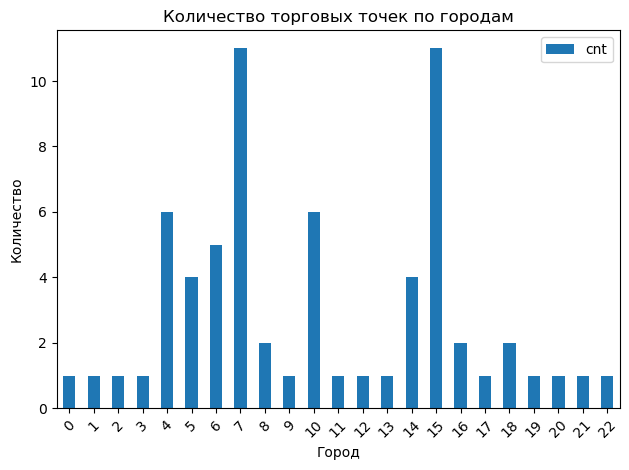

In [29]:
region_group = region.groupby('city').agg(cnt=('id_trading_point', 'count')).reset_index()

plt.figure(figsize=(9, 6))
region_group.plot(kind='bar')
plt.title('Количество торговых точек по городам')
plt.xlabel('Город')
plt.ylabel('Количество')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Визуализировали торговых точек по городам - больше всего торговых точек в городах 
# Москва и Санкт-Петербург (по 11 шт.)

2. Объединение таблиц


Определим сумму платежей на каждого клиента

In [6]:
clients_payments = data.groupby('id_client').agg(sum_payments = ('amt_payment','sum')).reset_index()
clients_payments
# сумма платежей на каждого клиента 

,id_client,sum_payments
0,178561.0,3052.0
1,178562.0,2439.0
2,178563.0,768.0
3,178564.0,0.0
4,178565.0,958.0
...,...,...
29707,209630.0,6927.0
29708,209631.0,2090.0
29709,209632.0,2775.0
29710,209633.0,1673.0


Соединим (по клиенту) сгруппированную таблицу с платежами с клиентской таблицей

In [7]:
client_pay_nocity = clients.merge(clients_payments, on = 'id_client', how='left')

#Заполняем нулями те ячейки у которых NaN в столбце sum_payments и добавим города
client_pay_nocity['sum_payments'] = client_pay_nocity['sum_payments'].fillna(0)
client_pay_merged = client_pay_nocity.merge(region, on = 'id_trading_point', how='left')

#Создадим поле флаг платежа, который принимает значения 0 или 1 в зависимости от того, заплатил клиент или нет.
client_pay_merged['flag_pay'] = np.where(client_pay_merged['sum_payments'] == 0,0,1) 

client_pay_merged

,id_client,dtime_ad,nflag_test,id_trading_point,sum_payments,city,flag_pay
0,180844,2022-06-08 18:38:41.414,0,212,5349.0,Красноярск,1
1,226069,2022-07-11 16:28:38.511,1,54,0.0,Мурманск,0
2,183981,2022-06-16 12:23:59.289,1,991,6322.0,Казань,1
3,322530,2022-07-08 08:56:08.714,0,1015,0.0,Краснодар,0
4,254313,2022-06-19 22:18:01.770,1,453,0.0,Санкт-Петербург,0
...,...,...,...,...,...,...,...
55351,193038,2022-07-09 00:31:25.196,0,1015,5846.0,Краснодар,1
55352,244069,2022-08-08 00:12:31.319,1,991,0.0,Казань,0
55353,189084,2022-06-29 04:34:42.610,1,439,7146.0,Казань,1
55354,182758,2022-06-13 11:28:37.856,1,573,13720.0,Санкт-Петербург,1


3. Автоматизация статистических вычислений

Создадим функцию, которая будет вычислять значение t-критерия (критерия Стьюдента) и
p_value для сравнения средних и выводить сообщение о том, существует ли разница между средними.


In [8]:
def test_calc(r1, r2, alpha=0.05):
    t_stat, p_value = ttest_ind(r1, r2)

    if p_value < alpha:
        print('Различия статистически значимы')
    else:
        print('Нет статистически значимых различий')
    return t_stat, p_value

Создадим функцию, которая будет рассчитывать значение критерия Манна Уитни
и p_value для сравнения распределений и с помощью функции print выводить сообщение о том, 
существует ли разница между средними.

In [9]:
def mann_whitney_func(r1, r2, alpha=0.05):
    u_stat, p_value = stats.mannwhitneyu(r1, r2)

    if p_value < alpha:
        print('Различия статистически значимы')
    else:
        print('Нет статистически значимых различий')
    return u_stat, p_value

4. Чистка неверно заполненных точек

   
Создадим пустой список и запустим цикл по всем торговым точкам и добавим к этому списку все торговые точки, 
в которых в тестовой или в контрольной группе не было заплачено ни одного рубля ни одним клиентом.
   

In [10]:
pay_empty = []

for point in client_pay_merged['id_trading_point'].unique():
    point_data = client_pay_merged[client_pay_merged['id_trading_point']==point]
    test_payments = point_data[point_data['nflag_test'] == 1]['sum_payments'].sum()
    control_payments = point_data[point_data['nflag_test'] == 0]['sum_payments'].sum()
    if test_payments == 0 or control_payments == 0:
         pay_empty.append(point)
print(f"Торговых точек с нулевыми платежами: {len(pay_empty)}")
pay_empty

Торговых точек с нулевыми платежами: 15


[np.int64(1015),
 np.int64(866),
 np.int64(1099),
 np.int64(739),
 np.int64(46),
 np.int64(228),
 np.int64(26),
 np.int64(603),
 np.int64(810),
 np.int64(800),
 np.int64(7),
 np.int64(23),
 np.int64(4),
 np.int64(1),
 np.int64(13)]

Создадим еще один пустой список, запустим цикл по всем торговым точкам и добавим к этому списку 
все торговые точки, в которых пустует или контрольная, или тестовая группа.

In [11]:
group_empty = []

for point in client_pay_merged['id_trading_point'].unique():
    point_data = client_pay_merged[client_pay_merged['id_trading_point']==point]
    test_gr = point_data[point_data['nflag_test'] == 1]['nflag_test'].count()
    control_gr = point_data[point_data['nflag_test'] == 0]['nflag_test'].count()
    if test_gr == 0 or control_gr == 0:
         group_empty.append(point)
print(f"Торговых точек с нулевыми платежами: {len(group_empty)}")

Торговых точек с нулевыми платежами: 8


5. Расчет общих результатов A/B-теста

In [12]:
df_final = client_pay_merged[~client_pay_merged['id_trading_point'].isin(pay_empty+group_empty)]
df_final

,id_client,dtime_ad,nflag_test,id_trading_point,sum_payments,city,flag_pay
0,180844,2022-06-08 18:38:41.414,0,212,5349.0,Красноярск,1
1,226069,2022-07-11 16:28:38.511,1,54,0.0,Мурманск,0
2,183981,2022-06-16 12:23:59.289,1,991,6322.0,Казань,1
4,254313,2022-06-19 22:18:01.770,1,453,0.0,Санкт-Петербург,0
5,195818,2022-07-16 01:30:59.088,1,2652,4021.0,Москва,1
...,...,...,...,...,...,...,...
55350,188702,2022-06-28 06:16:25.664,0,453,1323.0,Санкт-Петербург,1
55352,244069,2022-08-08 00:12:31.319,1,991,0.0,Казань,0
55353,189084,2022-06-29 04:34:42.610,1,439,7146.0,Казань,1
55354,182758,2022-06-13 11:28:37.856,1,573,13720.0,Санкт-Петербург,1


5. Расчет общих результатов A/B-теста


Отбросим все торговые точки, которые были обнаружены в пункте 4.

Изобразим гистограмму платежей, на которой различными цветами изображены группы «тест» и «контроль».

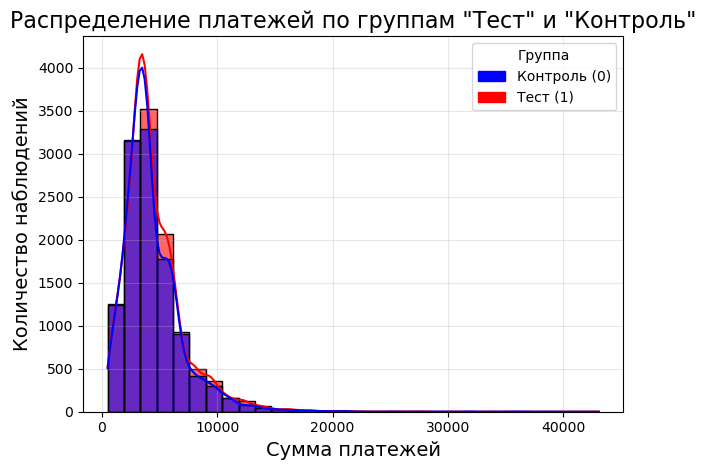

In [14]:
sns.histplot(data=df_final[df_final['sum_payments'] > 0 ], x='sum_payments', 
             hue='nflag_test', kde=True,  # добавить сглаженную кривую плотности
             bins=30, alpha=0.6,  # прозрачность
             palette={0: 'blue', 1: 'red'})

# Настройка графика
plt.title('Распределение платежей по группам "Тест" и "Контроль"', fontsize=16)
plt.xlabel('Сумма платежей', fontsize=14)
plt.ylabel('Количество наблюдений', fontsize=14)
plt.grid(alpha=0.3)

import matplotlib.patches as mpatches
blue_patch = mpatches.Patch(color='blue', label='Контроль (0)')
red_patch = mpatches.Patch(color='red', label='Тест (1)')
plt.legend(handles=[blue_patch, red_patch], title='Группа')

plt.tight_layout()
plt.show()

In [15]:
test_calc(df_final[df_final['nflag_test']==1]['sum_payments'],df_final[df_final['nflag_test']==0]['sum_payments'])


Различия статистически значимы


(np.float64(9.573285274103036), np.float64(1.0857547123769503e-21))

In [16]:
test_calc(df_final[df_final['nflag_test']==1]['flag_pay'],df_final[df_final['nflag_test']==0]['flag_pay'])

Различия статистически значимы


(np.float64(9.406024876422881), np.float64(5.384854454774238e-21))

In [17]:
mann_whitney_func(df_final[df_final['nflag_test']==1]['sum_payments'],df_final[df_final['nflag_test']==0]['sum_payments'])

Различия статистически значимы


(np.float64(270212972.5), np.float64(7.829376257720136e-25))

6. Сегментация результатов A/B-теста

In [18]:
df_msc = df_final[df_final['city']=='Москва']
df_spb = df_final[df_final['city']=='Санкт-Петербург']

Результаты АБ теста по различным городам

/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/630632224.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


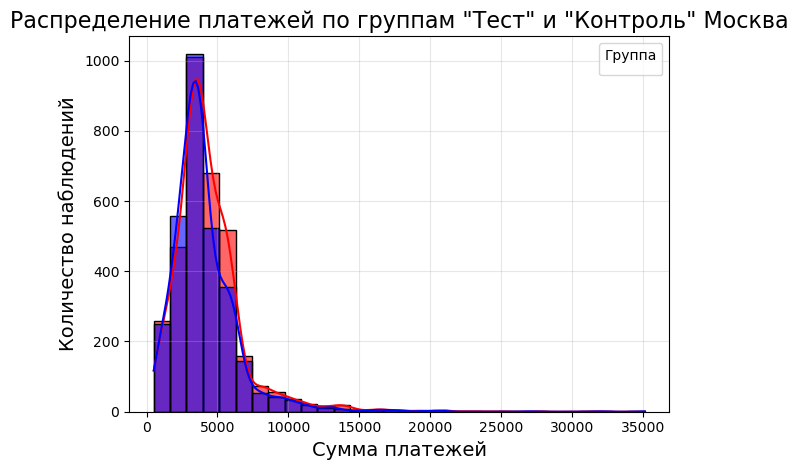

In [19]:
sns.histplot(data=df_msc[df_msc['sum_payments'] > 0 ], x='sum_payments', 
             hue='nflag_test', kde=True,  # добавить сглаженную кривую плотности
             bins=30, alpha=0.6,  # прозрачность
             palette={0: 'blue', 1: 'red'})

# Настройка графика
plt.title('Распределение платежей по группам "Тест" и "Контроль" Москва', fontsize=16)
plt.xlabel('Сумма платежей', fontsize=14)
plt.ylabel('Количество наблюдений', fontsize=14)
plt.grid(alpha=0.3)
plt.legend(title='Группа')
plt.tight_layout()
plt.show()


In [20]:
print('Москва')
print('T-test абсолютные платежи')
test_calc(df_msc[df_msc['nflag_test']==1]['sum_payments'],df_msc[df_msc['nflag_test']==0]['sum_payments'])
print()
print('T-test конверсия')
test_calc(df_msc[df_msc['nflag_test']==1]['flag_pay'],df_msc[df_msc['nflag_test']==0]['flag_pay'])
print()
print('Манна-Уитни - абсолютные платежи')
mann_whitney_func(df_msc[df_msc['nflag_test']==1]['sum_payments'],df_msc[df_msc['nflag_test']==0]['sum_payments'])

Москва
T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Различия статистически значимы


(np.float64(20643197.5), np.float64(8.65125657678773e-17))

/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/58177399.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


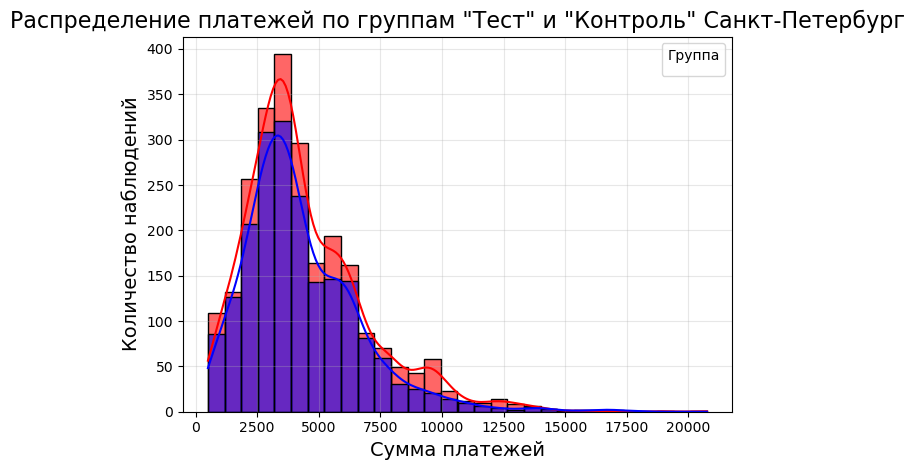

In [21]:
#Санкт-Петербург график

sns.histplot(data=df_spb[df_spb['sum_payments'] > 0 ], x='sum_payments', 
             hue='nflag_test', kde=True,  # добавить сглаженную кривую плотности
             bins=30, alpha=0.6,  # прозрачность
             palette={0: 'blue', 1: 'red'})

# Настройка графика
plt.title('Распределение платежей по группам "Тест" и "Контроль" Санкт-Петербург', fontsize=16)
plt.xlabel('Сумма платежей', fontsize=14)
plt.ylabel('Количество наблюдений', fontsize=14)
plt.grid(alpha=0.3)
plt.legend(title='Группа')
plt.tight_layout()
plt.show()

In [22]:
#Санкт-Петербург функции

print('Санкт-Петербург')
print('T-test абсолютные платежи')
test_calc(df_spb[df_spb['nflag_test']==1]['sum_payments'],df_spb[df_spb['nflag_test']==0]['sum_payments'])
print()
print('T-test конверсия')
test_calc(df_spb[df_spb['nflag_test']==1]['flag_pay'],df_spb[df_spb['nflag_test']==0]['flag_pay'])
print()
print('Манна-Уитни - абсолютные платежи')
mann_whitney_func(df_spb[df_spb['nflag_test']==1]['sum_payments'],df_spb[df_spb['nflag_test']==0]['sum_payments'])

Санкт-Петербург
T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Различия статистически значимы


(np.float64(10899685.5), np.float64(2.0392184217953754e-20))

Красноярск


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


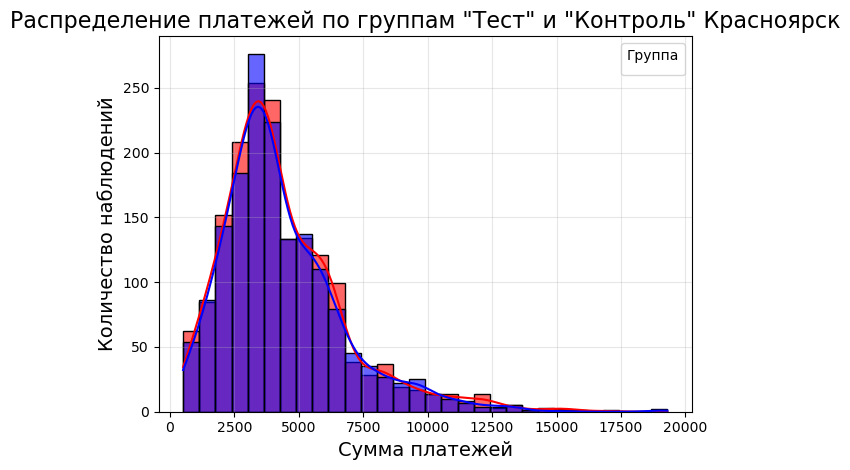

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Мурманск


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


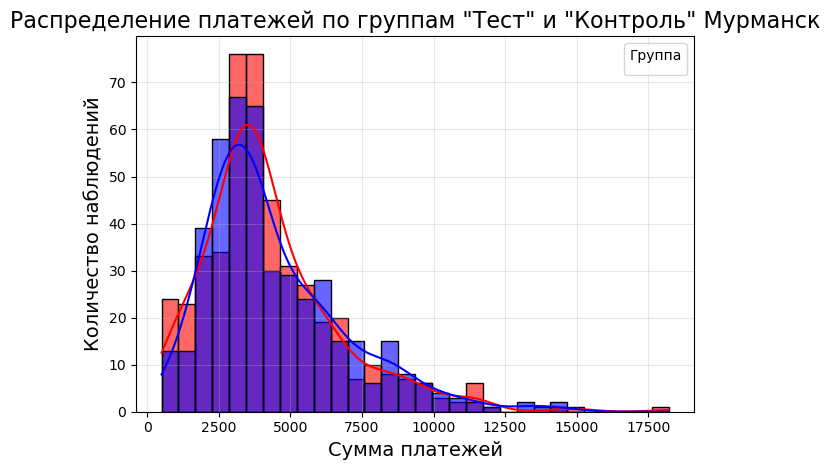

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Казань


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


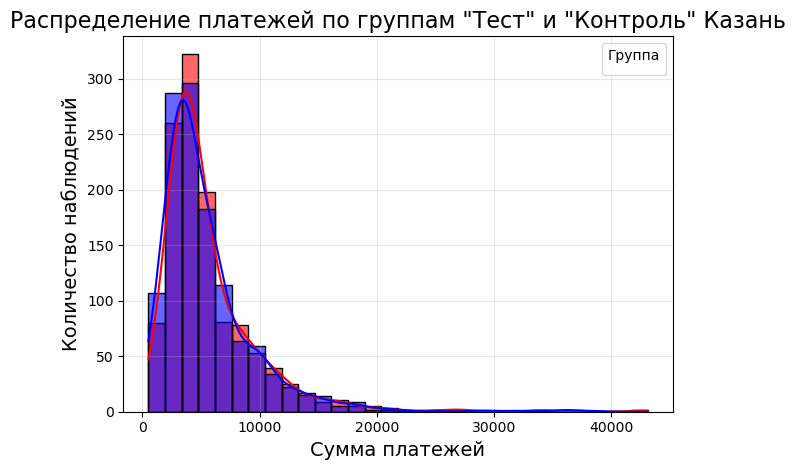

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Саратов


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


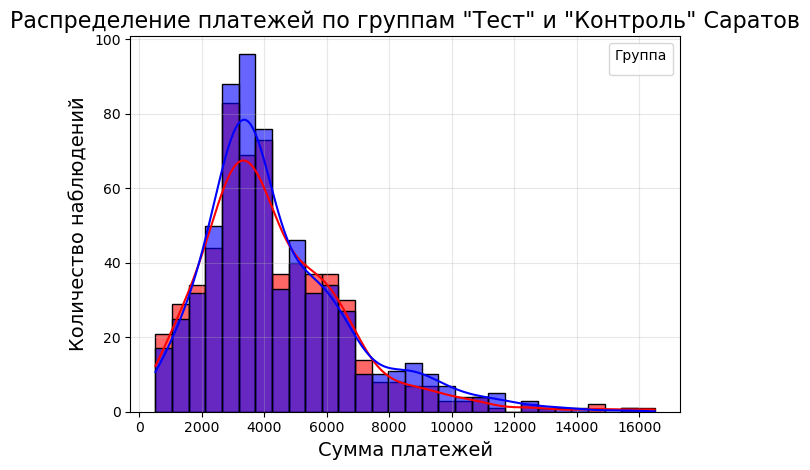

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Тольятти


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


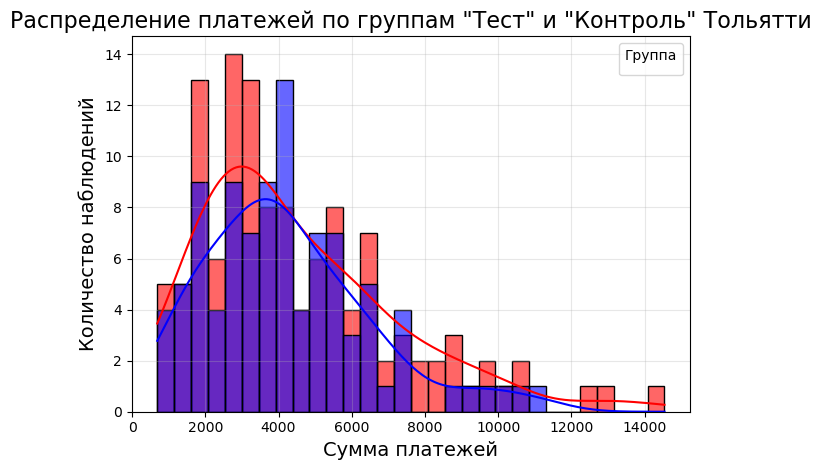

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Тюмень


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


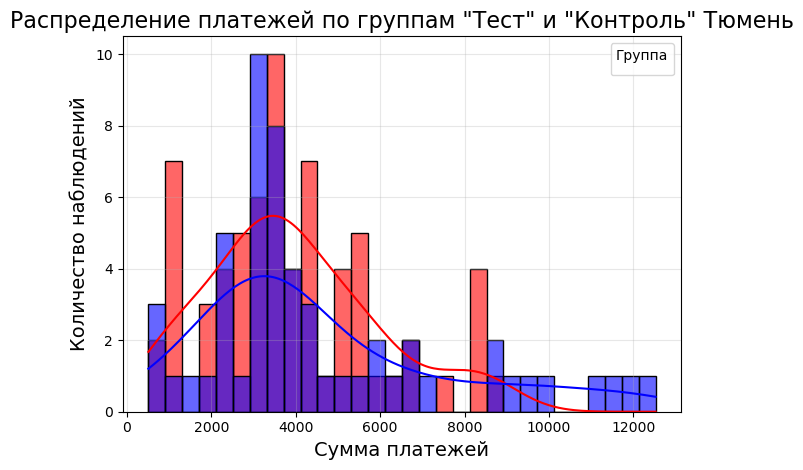

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Различия статистически значимы

Волгоград


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


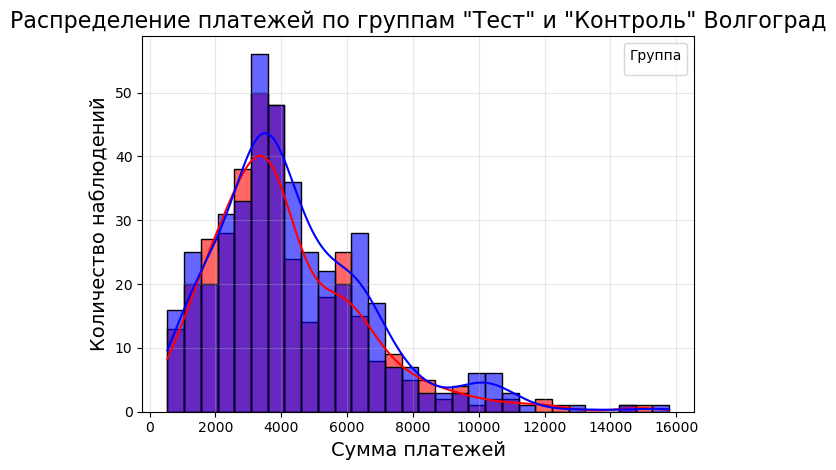

T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Различия статистически значимы

Сочи


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


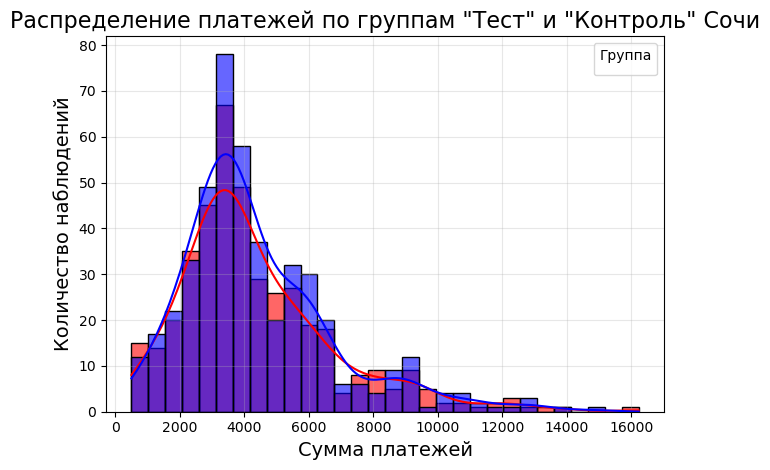

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Владимир


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


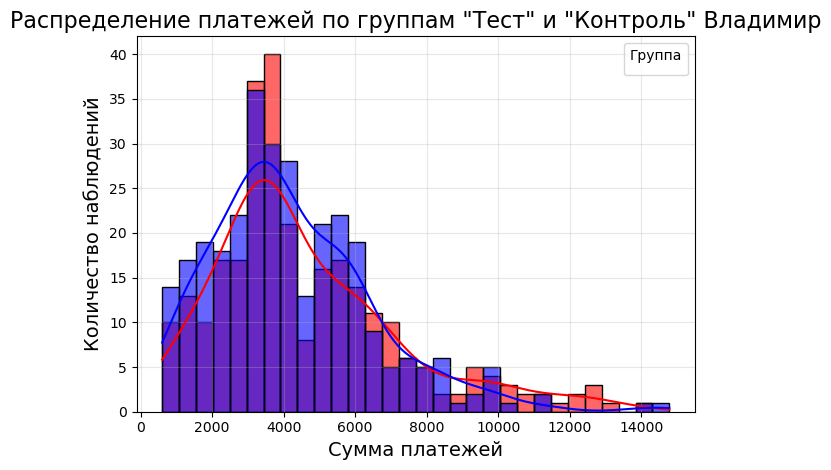

/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Различия статистически значимы

Самара


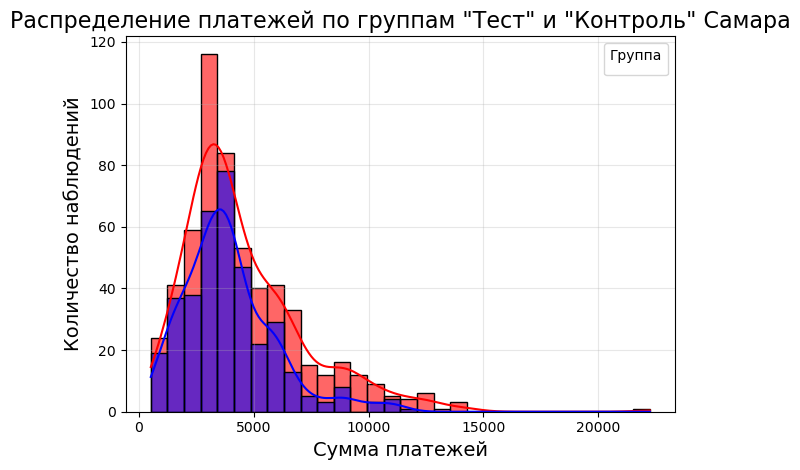

T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Различия статистически значимы

Краснодар


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


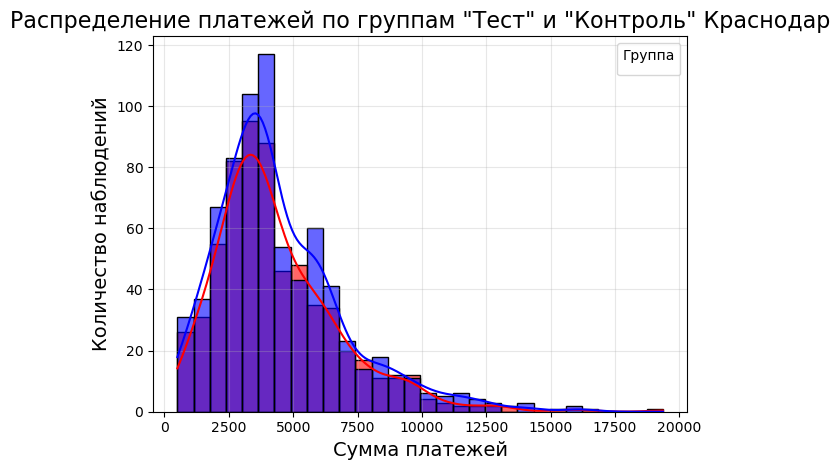

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Сахалинск


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


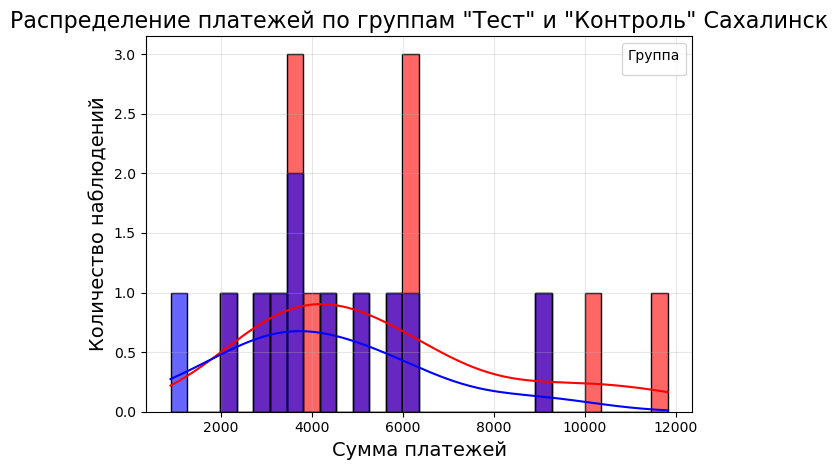

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Дмитров


/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/2763823049.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Группа')


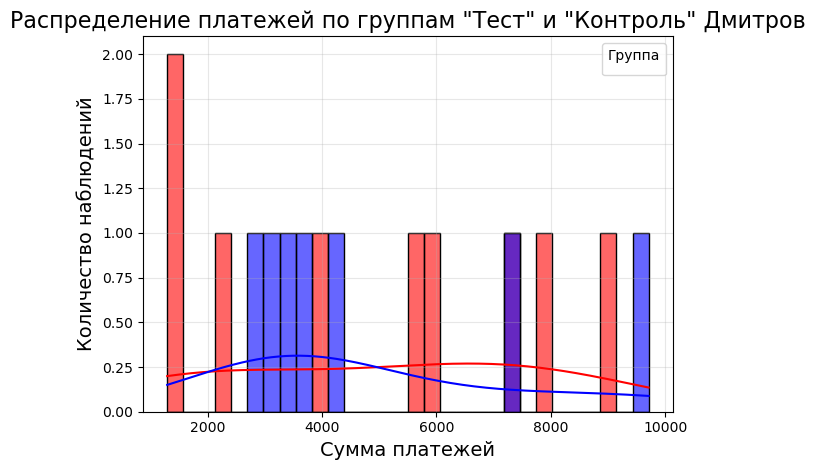

T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий



In [23]:
big_cities = ['Москва','Санкт-Петербург']
other_cities = [city for city in df_final['city'].unique() if city not in big_cities]

for i in other_cities:
    df_city = df_final[df_final['city']==i]

    print(i)
    sns.histplot(data=df_city[df_city['sum_payments'] > 0 ], x='sum_payments', 
             hue='nflag_test', kde=True,  # добавить сглаженную кривую плотности
             bins=30, alpha=0.6,  # прозрачность
             palette={0: 'blue', 1: 'red'})
    # Настройка графика
    plt.title(f'Распределение платежей по группам "Тест" и "Контроль" {i}', fontsize=16)
    plt.xlabel('Сумма платежей', fontsize=14)
    plt.ylabel('Количество наблюдений', fontsize=14)
    plt.grid(alpha=0.3)
    plt.legend(title='Группа')
    plt.tight_layout()
    plt.show()
    
    print('T-test абсолютные платежи')
    test_calc(df_city[df_city['nflag_test']==1]['sum_payments'],df_city[df_city['nflag_test']==0]['sum_payments'])
    print()
    print('T-test конверсия')
    test_calc(df_city[df_city['nflag_test']==1]['flag_pay'],df_city[df_city['nflag_test']==0]['flag_pay'])
    print()
    print('Манна-Уитни - абсолютные платежи')
    mann_whitney_func(df_city[df_city['nflag_test']==1]['sum_payments'],df_city[df_city['nflag_test']==0]['sum_payments'])
    print()

    

Вывод: 
В разных городах получились разные значения, говоря о крупных (Москва и Санкт-Петербург), отметим, 
что значения являются статистически значимыми, значит, сравнение средних платежей, конверсии в платеж прошло успешно и показало, 
что тестовая группа имеет лучшие результаты


7. Отчет по A/B-тесту

In [24]:
for i in df_final['city'].unique():
    df_city = df_final[df_final['city']==i]
    for j in df_city['id_trading_point'].unique():
        df_city_point = df_city[df_city['id_trading_point']==j]
        
    print(i,j)
    print('T-test абсолютные платежи')
    test_calc(df_city_point[df_city_point['nflag_test']==1]['sum_payments'],df_city_point[df_city_point['nflag_test']==0]['sum_payments'])
    print()
    print('T-test конверсия')
    test_calc(df_city_point[df_city_point['nflag_test']==1]['flag_pay'],df_city_point[df_city_point['nflag_test']==0]['flag_pay'])
    print()
    print('Манна-Уитни - абсолютные платежи')
    mann_whitney_func(df_city_point[df_city_point['nflag_test']==1]['sum_payments'],df_city_point[df_city_point['nflag_test']==0]['sum_payments'])
    print()

Красноярск 277
T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Мурманск 55
T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Казань 439
T-test абсолютные платежи
Нет статистически значимых различий

T-test конверсия
Нет статистически значимых различий

Манна-Уитни - абсолютные платежи
Нет статистически значимых различий

Санкт-Петербург 891
T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Различия статистически значимы

Москва 1002
T-test абсолютные платежи
Различия статистически значимы

T-test конверсия
Различия статистически значимы

Манна-Уитни - абсолютные платежи
Различия статистически значимы

Саратов 82
T-test абсолют

In [25]:
df_result = pd.DataFrame(columns=['city', 'id_trading_point', 'count_test', 'count_control', 'count_all',
                                  'avg_test', 'avg_control', 'diff', 'sigma_test', 'sigma_control',
                                  'abs_ttest_s', 'abs_ttest_p', 'pr_ttest_s', 'pr_ttest_p', 'mw_s', 'mw_p'])

for i in df_final['city'].unique():
    df_loc = df_final[df_final['city'] == i]

    for j in df_loc['id_trading_point'].unique():
        df_loc_f = df_loc[df_loc['id_trading_point'] == j]

        count_test = len(df_loc_f[df_loc_f['nflag_test'] == 1])
        count_control = len(df_loc_f[df_loc_f['nflag_test'] == 0])
        count_all = count_test + count_control
        sigma_test = df_loc_f[df_loc_f['nflag_test'] == 1]['sum_payments'].std()
        sigma_control = df_loc_f[df_loc_f['nflag_test'] == 0]['sum_payments'].std()

        avg_test = np.mean(df_loc_f[df_loc_f['nflag_test'] == 1]['sum_payments'])
        avg_control = np.mean(df_loc_f[df_loc_f['nflag_test'] == 0]['sum_payments'])
        diff = avg_test - avg_control

        s_a, p_a = test_calc(df_loc_f[df_loc_f['nflag_test'] == 1]['sum_payments'], df_loc_f[df_loc_f['nflag_test'] == 0]['sum_payments'])
        s_p, p_p = test_calc(df_loc_f[df_loc_f['nflag_test'] == 1]['flag_pay'], df_loc_f[df_loc_f['nflag_test'] == 0]['flag_pay'])
        m_s, m_p = mann_whitney_func(df_loc_f[df_loc_f['nflag_test'] == 1]['sum_payments'], df_loc_f[df_loc_f['nflag_test'] == 0]['sum_payments'])

        new_row = pd.DataFrame({
            'city': [i],
            'id_trading_point': [j],
            'count_test': [count_test],
            'count_control': [count_control],
            'count_all': [count_all],
            'avg_test': [avg_test],
            'avg_control': [avg_control],
            'sigma_test': [sigma_test],
            'sigma_control': [sigma_control],
            'diff': [diff],
            'abs_ttest_s': [s_a],
            'abs_ttest_p': [p_a],
            'pr_ttest_s': [s_p],
            'pr_ttest_p': [p_p],
            'mw_s': [m_s],
            'mw_p': [m_p]
        })

        df_result = pd.concat([df_result, new_row], ignore_index=True)

df_result['nflag_diff'] = np.where((df_result['abs_ttest_p'] < .05) & (df_result['diff'] > 0), 'Positive',
                              np.where((df_result['abs_ttest_p'] < .05) & (df_result['diff'] < 0), 'Negative', 'No diff'))
df_result['percent_count'] = (df_result['count_all'] / df_result['count_all'].sum())
df_result


Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Различия статистически значимы
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различий
Нет статистически значимых различ

/var/folders/3k/3lfv4n6x1q59x7xhslpr1ppm0000gn/T/ipykernel_2751/782332688.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_result = pd.concat([df_result, new_row], ignore_index=True)


,city,id_trading_point,count_test,count_control,count_all,avg_test,avg_control,diff,sigma_test,sigma_control,abs_ttest_s,abs_ttest_p,pr_ttest_s,pr_ttest_p,mw_s,mw_p,nflag_diff,percent_count
0,Красноярск,212,593,575,1168,2144.317032,2222.052174,-77.735142,2708.588724,2785.116250,-0.483585,6.287709e-01,0.450975,6.520918e-01,169439.0,8.468854e-01,No diff,0.025773
1,Красноярск,278,535,489,1024,2499.345794,2185.214724,314.131070,2915.995329,2574.915597,1.820268,6.901056e-02,0.822651,4.108986e-01,136856.5,1.782204e-01,No diff,0.022596
2,Красноярск,202,551,565,1116,2927.341198,2730.378761,196.962437,2956.686241,2737.885785,1.155073,2.483083e-01,-0.625387,5.318451e-01,159950.0,4.142330e-01,No diff,0.024626
3,Красноярск,444,650,562,1212,2404.106154,2545.734875,-141.628722,2810.828487,2797.138764,-0.876740,3.808017e-01,-0.748236,4.544630e-01,176313.0,2.766352e-01,No diff,0.026744
4,Красноярск,277,708,709,1417,2285.750000,2431.365303,-145.615303,2712.677878,2868.587569,-0.981705,3.264128e-01,-0.344097,7.308242e-01,246121.5,5.059942e-01,No diff,0.031268
5,Мурманск,54,633,640,1273,1702.714060,1688.512500,14.201560,2565.132440,2628.012490,0.097556,9.223005e-01,0.155600,8.763729e-01,204686.0,7.117070e-01,No diff,0.02809
6,Мурманск,55,422,425,847,2109.106635,2111.272941,-2.166306,2790.993385,2804.223188,-0.011268,9.910125e-01,1.131579,2.581326e-01,90987.5,6.923131e-01,No diff,0.01869
7,Казань,991,270,294,564,3249.281481,2452.986395,796.295087,4719.592601,3633.935858,2.255258,2.450100e-02,1.260334,2.080719e-01,43029.0,6.467167e-02,Positive,0.012445
8,Казань,699,482,494,976,2422.286307,2574.352227,-152.065920,3906.817897,4082.851356,-0.594254,5.524804e-01,-1.514639,1.301883e-01,114960.5,3.096216e-01,No diff,0.021537
9,Казань,477,382,386,768,2259.623037,2496.987047,-237.364010,3482.846094,3881.994719,-0.891593,3.728909e-01,-0.309729,7.568515e-01,72517.0,6.640893e-01,No diff,0.016947


In [26]:
df_result

,city,id_trading_point,count_test,count_control,count_all,avg_test,avg_control,diff,sigma_test,sigma_control,abs_ttest_s,abs_ttest_p,pr_ttest_s,pr_ttest_p,mw_s,mw_p,nflag_diff,percent_count
0,Красноярск,212,593,575,1168,2144.317032,2222.052174,-77.735142,2708.588724,2785.116250,-0.483585,6.287709e-01,0.450975,6.520918e-01,169439.0,8.468854e-01,No diff,0.025773
1,Красноярск,278,535,489,1024,2499.345794,2185.214724,314.131070,2915.995329,2574.915597,1.820268,6.901056e-02,0.822651,4.108986e-01,136856.5,1.782204e-01,No diff,0.022596
2,Красноярск,202,551,565,1116,2927.341198,2730.378761,196.962437,2956.686241,2737.885785,1.155073,2.483083e-01,-0.625387,5.318451e-01,159950.0,4.142330e-01,No diff,0.024626
3,Красноярск,444,650,562,1212,2404.106154,2545.734875,-141.628722,2810.828487,2797.138764,-0.876740,3.808017e-01,-0.748236,4.544630e-01,176313.0,2.766352e-01,No diff,0.026744
4,Красноярск,277,708,709,1417,2285.750000,2431.365303,-145.615303,2712.677878,2868.587569,-0.981705,3.264128e-01,-0.344097,7.308242e-01,246121.5,5.059942e-01,No diff,0.031268
5,Мурманск,54,633,640,1273,1702.714060,1688.512500,14.201560,2565.132440,2628.012490,0.097556,9.223005e-01,0.155600,8.763729e-01,204686.0,7.117070e-01,No diff,0.02809
6,Мурманск,55,422,425,847,2109.106635,2111.272941,-2.166306,2790.993385,2804.223188,-0.011268,9.910125e-01,1.131579,2.581326e-01,90987.5,6.923131e-01,No diff,0.01869
7,Казань,991,270,294,564,3249.281481,2452.986395,796.295087,4719.592601,3633.935858,2.255258,2.450100e-02,1.260334,2.080719e-01,43029.0,6.467167e-02,Positive,0.012445
8,Казань,699,482,494,976,2422.286307,2574.352227,-152.065920,3906.817897,4082.851356,-0.594254,5.524804e-01,-1.514639,1.301883e-01,114960.5,3.096216e-01,No diff,0.021537
9,Казань,477,382,386,768,2259.623037,2496.987047,-237.364010,3482.846094,3881.994719,-0.891593,3.728909e-01,-0.309729,7.568515e-01,72517.0,6.640893e-01,No diff,0.016947


In [27]:
pip install XlsxWriter

Note: you may need to restart the kernel to use updated packages.


In [28]:
writer = pd.ExcelWriter('Калькулятор АБ теста2.xlsx', engine='xlsxwriter')

df_result[df_result['nflag_diff']=='Positive'].to_excel(writer, sheet_name='Успешные ТТ', index = False)
df_result[df_result['nflag_diff']=='Negative'].to_excel(writer, sheet_name='Неуспешные ТТ', index = False)
df_result[df_result['nflag_diff']=='No diff'].to_excel(writer, sheet_name='Нет разницы', index = False)

writer.close()